In [1]:
'''все необходимые импорты'''

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from pathlib import Path
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score)

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Intial block

In [2]:
'''загрузка данных'''
data_dir = Path("data/raw")
if not data_dir.is_dir():
    data_dir = Path("../data/raw")

encounters = pd.read_csv(
    data_dir / "diabetic_data.csv",
    keep_default_na=False,
    na_values=["?"],
    dtype={
        "diag_1": "string",
        "diag_2": "string",
        "diag_3": "string",
        "payer_code": "string",
    },)

mapping_rows = pd.read_csv(
    data_dir / "IDS_mapping.csv",
    header=None,
    names=["code", "description"],
    dtype="string",
    keep_default_na=False,)

is_section_header = mapping_rows["description"].eq("description")
mapping_rows["field"] = mapping_rows["code"].where(is_section_header).ffill()

is_code = mapping_rows["code"].str.fullmatch(r"\d+")
id_mapping = mapping_rows.loc[is_code, ["field", "code", "description"]].copy()
id_mapping["code"] = id_mapping["code"].astype(int)

In [3]:
'''первичный обзор'''

assert encounters["encounter_id"].is_unique
assert set(encounters["readmitted"]) == {"<30", ">30", "NO"}
assert not id_mapping.duplicated(["field", "code"]).any()

'''смотрим на размеры выборки по госпитализациям'''
display(pd.Series({
    "Госпитализации": len(encounters),
    "Пациенты": encounters["patient_nbr"].nunique(),
    "Столбцы": encounters.shape[1]}, name="Количество").to_frame())

'''смотрим на профили стобцов'''
preview_columns = [
    "encounter_id", "patient_nbr", "age",
    "time_in_hospital", "discharge_disposition_id", "readmitted"]
display(encounters[preview_columns].head())

column_profile = pd.DataFrame({
    "Тип": encounters.dtypes.astype(str),
    "Уникальных значений": encounters.nunique(),
    "Пропуски, %": (encounters.isna().mean() * 100).round(2)})

'''чекаем пропуски, и в какой процент по пропускам'''
display(column_profile.sort_values("Пропуски, %", ascending=False))
display(id_mapping.query("field == 'discharge_disposition_id'").head())

,Количество
Госпитализации,101766
Пациенты,71518
Столбцы,50


,encounter_id,patient_nbr,age,time_in_hospital,discharge_disposition_id,readmitted
0,2278392,8222157,[0-10),1,25,NO
1,149190,55629189,[10-20),3,1,>30
2,64410,86047875,[20-30),2,1,NO
3,500364,82442376,[30-40),2,1,NO
4,16680,42519267,[40-50),1,1,NO


,Тип,Уникальных значений,"Пропуски, %"
weight,str,9,96.86
medical_specialty,str,72,49.08
payer_code,string,17,39.56
race,str,5,2.23
diag_3,string,789,1.40
diag_2,string,748,0.35
diag_1,string,716,0.02
encounter_id,int64,101766,0.00
tolazamide,str,3,0.00
glyburide,str,4,0.00


,field,code,description
11,discharge_disposition_id,1,Discharged to home
12,discharge_disposition_id,2,Discharged/transferred to another short term h...
13,discharge_disposition_id,3,Discharged/transferred to SNF
14,discharge_disposition_id,4,Discharged/transferred to ICF
15,discharge_disposition_id,5,Discharged/transferred to another type of inpa...


#### смотрим на исходы выписки

In [4]:
## Повторная госпитализация по исходу выписки
discharge_labels = (
    id_mapping.loc[id_mapping["field"].eq("discharge_disposition_id")]
    .set_index("code")["description"].rename("Исход выписки"))

target_order = ["<30", ">30", "NO"]
counts = pd.crosstab(
    encounters["discharge_disposition_id"],
    encounters["readmitted"]).reindex(columns=target_order, fill_value=0)

totals = counts.sum(axis=1)
shares = counts.div(totals, axis=0).mul(100).round(1).add_suffix(", %")

discharge_summary = (
    counts.assign(Всего=totals)
    .join(shares)
    .join(discharge_labels)
    .sort_values("Всего", ascending=False))

assert discharge_summary["Всего"].sum() == len(encounters)
display(discharge_summary[
    ["Исход выписки", "Всего", "<30", "<30, %", ">30", ">30, %", "NO", "NO, %"]])

,Исход выписки,Всего,<30,"<30, %",>30,">30, %",NO,"NO, %"
discharge_disposition_id,,,,,,,,
1,Discharged to home,60234,5602,9.3,21517,35.7,33115,55.0
3,Discharged/transferred to SNF,13954,2046,14.7,4916,35.2,6992,50.1
6,Discharged/transferred to home with home healt...,12902,1638,12.7,5362,41.6,5902,45.7
18,NULL,3691,459,12.4,1027,27.8,2205,59.7
2,Discharged/transferred to another short term h...,2128,342,16.1,668,31.4,1118,52.5
22,Discharged/transferred to another rehab fac in...,1993,552,27.7,519,26.0,922,46.3
11,Expired,1642,0,0.0,0,0.0,1642,100.0
5,Discharged/transferred to another type of inpa...,1184,247,20.9,350,29.6,587,49.6
25,Not Mapped,989,92,9.3,376,38.0,521,52.7


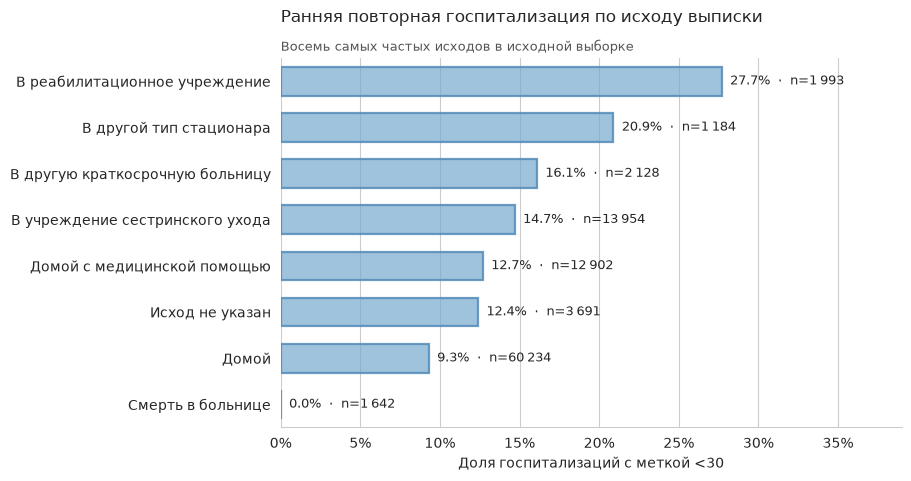

In [5]:
discharge_plot_labels = {
    1: "Домой",
    2: "В другую краткосрочную больницу",
    3: "В учреждение сестринского ухода",
    5: "В другой тип стационара",
    6: "Домой с медицинской помощью",
    11: "Смерть в больнице",
    18: "Исход не указан",
    22: "В реабилитационное учреждение",
}

discharge_plot = discharge_summary.head(8).sort_values("<30, %", ascending=False).copy()
discharge_plot["Группа"] = (
    discharge_plot.index.to_series().map(discharge_plot_labels)
    .fillna(discharge_plot["Исход выписки"])
)

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 4.7), layout="constrained")
    sns.barplot(
        data=discharge_plot, x="<30, %", y="Группа",
        color="#76A9CFB3", saturation=1, edgecolor="#538BB9D9",
        linewidth=1.6, width=0.62, ax=ax,
    )
    for bar in ax.containers[0]:
        bar.set_facecolor("#76A9CFB3")

    ax.bar_label(
        ax.containers[0],
        labels=[f"{rate:.1f}%  ·  n={total:,}".replace(",", " ")
                for rate, total in zip(discharge_plot["<30, %"], discharge_plot["Всего"])],
        padding=6,
        fontsize=9,
    )
    ax.set_xlim(0, 39)
    ax.set_xticks(range(0, 36, 5), labels=[f"{x}%" for x in range(0, 36, 5)])
    ax.set_title("Ранняя повторная госпитализация по исходу выписки", loc="left", pad=26)
    ax.text(0, 1.02, "Восемь самых частых исходов в исходной выборке",
            transform=ax.transAxes, color="#555555", fontsize=9)
    ax.set(xlabel="Доля госпитализаций с меткой <30", ylabel=None)
    sns.despine(ax=ax, left=True)

plt.show()

**Вывод:** Доля ранних повторных госпитализаций различается по исходам выписки: 9,3% при выписке домой и 27,7% при переводе на реабилитацию. Для прогноза при выписке живого пациента предлагаем исключить коды смерти и отдельно проверить, как на результаты влияет включение выписок в хоспис.

In [6]:
'''собираем рабочую выборку'''

death_codes = {11, 19, 20, 21}
cohort = encounters.loc[
    ~encounters["discharge_disposition_id"].isin(death_codes)].copy()
cohort["readmitted_30d"] = cohort["readmitted"].eq("<30").astype(int)

display(pd.Series({
    "Госпитализации": f"{len(cohort):,}",
    "Пациенты": f"{cohort['patient_nbr'].nunique():,}",
    "Доля ранних повторных госпитализаций": f"{cohort['readmitted_30d'].mean():.2%}"
}).to_frame("Рабочая выборка"))

,Рабочая выборка
Госпитализации,"100,114"
Пациенты,"70,439"
Доля ранних повторных госпитализаций,11.34%


#### смотрим сколько госпитализаций приходится на пациента

пациенты с несколькими записями: 23.4%
доля строк этих пациентов: 46.1%


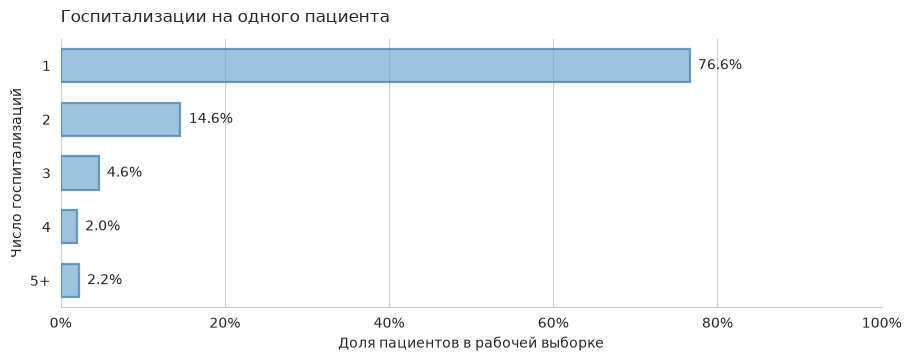

In [7]:
encounters_per_patient = cohort.groupby("patient_nbr").size()
repeat_patients = encounters_per_patient.gt(1)

print(f"пациенты с несколькими записями: {repeat_patients.mean():.1%}")
print(f"доля строк этих пациентов: {encounters_per_patient[repeat_patients].sum() / len(cohort):.1%}")

patient_counts = (
    encounters_per_patient.clip(upper=5)
    .value_counts().reindex(range(1, 6), fill_value=0))

patient_distribution = pd.DataFrame({
    "Госпитализаций": ["1", "2", "3", "4", "5+"],
    "Доля, %": patient_counts.to_numpy() / patient_counts.sum() * 100,
})

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    sns.barplot(
        data=patient_distribution, x="Доля, %", y="Госпитализаций",
        color="#76A9CFB3", saturation=1, edgecolor="#538BB9D9",
        linewidth=1.6, width=0.62, ax=ax,
    )
    for bar in ax.containers[0]:
        bar.set_facecolor("#76A9CFB3")

    ax.bar_label(
        ax.containers[0],
        labels=[f"{share:.1f}%" for share in patient_distribution["Доля, %"]],
        padding=6,
    )
    ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 20), labels=[f"{x}%" for x in range(0, 101, 20)])
    ax.set_title("Госпитализации на одного пациента", loc="left", pad=12)
    ax.set(xlabel="Доля пациентов в рабочей выборке", ylabel="Число госпитализаций")
    sns.despine(ax=ax, left=True)

plt.show()